# Ensemble and model diagnostics

## Questions

1. Apakah ensemble memperbaiki ranking risiko dan biaya keputusan?
2. Apakah F1 rendah terutama berkaitan dengan threshold berbasis biaya?
3. Seberapa besar distribusi skor default dan non-default bertumpang tindih?
4. Apakah model dasar memberikan ranking yang berbeda?
5. Apakah probabilitas terlihat konsisten dengan frekuensi default?

## Experiments

- Tuned XGBoost, LightGBM, dan CatBoost sebagai pembanding.
- Equal-weight blending: XGBoost + LightGBM.
- Equal-weight blending: XGBoost + LightGBM + CatBoost.
- Stacking XGBoost + LightGBM dengan Logistic Regression.

Primary policy:
Threshold OOF yang meminimalkan 5 × FN + FP.

Diagnostic policy:
Threshold OOF yang memaksimalkan F1. Kebijakan ini belum digunakan
sebagai threshold deployment.

## Evaluation scope

Stacking menggunakan 5 outer folds dan 3 inner folds.
Preprocessing setiap model dasar berada di dalam pipeline.

Parameter model dasar telah dipilih dari eksperimen training sebelumnya.
Evaluasi ini tidak mengulang hyperparameter search di setiap outer fold.
Karena itu, hasil tetap merupakan development comparison dan dapat
mengandung bias pemilihan parameter.

Test set tetap dikarantina.

In [1]:
import hashlib
import json

from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src import config
from src.data_loader import load_and_split
from src.ensemble import diagnose_oof, run_stacking_oof
from src.feature_engineering import CreditFeatureEngineer
from src.preprocess import build_preprocessor


split = load_and_split()
X_train = split.X_train
y_train = split.y_train

dataset_sha256 = hashlib.sha256(
    config.DATA_PATH.read_bytes()
).hexdigest()


def latest_search_directory(experiment_name: str) -> Path:
    """Mencari ringkasan pencarian lengkap yang paling baru."""
    root = config.EXPERIMENTS_DIR / experiment_name

    if not root.is_dir():
        raise FileNotFoundError(f"Laporan tidak ditemukan: {root}")

    candidates = [
        directory
        for directory in root.iterdir()
        if directory.is_dir()
        and (
            directory / config.EXPERIMENT_FILES["summary"]
        ).is_file()
    ]

    if not candidates:
        raise FileNotFoundError(f"Ringkasan kosong: {root}")

    return max(candidates, key=lambda directory: directory.name)


source_directories = {
    "xgb": (
        config.EXPERIMENTS_DIR
        / "xgb_optuna_v07"
        / "9d97e38c114bd0a2"
    ),
    "lgbm": latest_search_directory(
        "lgbm_aggregate_search_v03"
    ),
    "cat": (
        config.EXPERIMENTS_DIR
        / "cat_optuna_v06"
        / "36ef05f4e5af6381"
    ),
}


def load_candidate(directory: Path) -> dict[str, Any]:
    """Memuat kandidat biaya terendah dan provenance laporannya."""
    search = pd.read_csv(
        directory / config.EXPERIMENT_FILES["summary"]
    ).sort_values(
        "oof_cost_per_1000",
        ignore_index=True,
    )

    selected = search.iloc[0]

    search_metadata = json.loads(
        (
            directory / config.EXPERIMENT_FILES["metadata"]
        ).read_text(encoding="utf-8")
    )

    report_dir = Path(str(selected["report_dir"]))

    report_metadata = json.loads(
        (
            report_dir / config.EXPERIMENT_FILES["metadata"]
        ).read_text(encoding="utf-8")
    )

    expected_values = {
        "dataset_sha256": dataset_sha256,
        "cv_folds": config.CV_FOLDS,
        "cv_random_state": config.CV_RANDOM_STATE,
        "false_negative_cost": config.FALSE_NEGATIVE_COST,
        "false_positive_cost": config.FALSE_POSITIVE_COST,
    }

    for key, expected in expected_values.items():
        if report_metadata[key] != expected:
            raise ValueError(
                f"{report_dir}: konfigurasi {key} berbeda."
            )

    predictions = pd.read_csv(
        report_dir / config.EXPERIMENT_FILES["oof_predictions"],
        float_precision="round_trip",
    )

    parameters = {
        **search_metadata.get("base_parameters", {}),
        **json.loads(str(selected["parameters"])),
    }

    return {
        "experiment_id": str(selected["experiment_id"]),
        "report_dir": str(report_dir),
        "parameters": parameters,
        "predictions": predictions,
    }


sources = {
    name: load_candidate(directory)
    for name, directory in source_directories.items()
}

alignment_columns = ["source_row_index", "fold", "y_true"]

reference = sources["xgb"]["predictions"][
    alignment_columns
].reset_index(drop=True)

if not np.array_equal(
    reference["source_row_index"].to_numpy(),
    X_train.index.to_numpy(),
):
    raise ValueError("Urutan atau anggota training set berubah.")

if not np.array_equal(
    reference["y_true"].to_numpy(),
    y_train.to_numpy(),
):
    raise ValueError("Label training berbeda.")

for name, source in sources.items():
    current = source["predictions"][
        alignment_columns
    ].reset_index(drop=True)

    if not reference.equals(current):
        raise ValueError(f"Baris atau fold {name} berbeda.")


def make_base_pipeline(
    name: str,
    parameters: dict[str, Any],
) -> Pipeline:
    """Membangun ulang pipeline agregat XGBoost atau LightGBM."""
    model_parameters = dict(parameters)
    model_parameters.pop("feature_set", None)

    if name == "xgb":
        model = XGBClassifier(
            **(
                config.XGB_BASELINE_PARAMS
                | model_parameters
                | {"device": "cpu", "n_jobs": 4}
            )
        )
    elif name == "lgbm":
        model = LGBMClassifier(
            **(
                config.LGBM_BASELINE_PARAMS
                | model_parameters
                | {"n_jobs": 4}
            )
        )
    else:
        raise ValueError(f"Model tidak didukung: {name}")

    features = tuple(config.FE_AGGREGATE_COLUMNS)

    preprocessor = build_preprocessor(
        numeric_scaling="none",
        additional_numeric_columns=features,
    ).set_output(transform="pandas")

    return Pipeline(
        [
            (
                "feature_engineering",
                CreditFeatureEngineer(features=features),
            ),
            ("preprocess", preprocessor),
            ("model", model),
        ]
    )


base_pipelines = {
    name: make_base_pipeline(
        name,
        sources[name]["parameters"],
    )
    for name in ("xgb", "lgbm")
}

probability_matrix = pd.DataFrame(
    {
        name: source["predictions"][
            "probability_default"
        ].to_numpy()
        for name, source in sources.items()
    }
)

print("Kandidat tersimpan:")
for name, source in sources.items():
    print(f"{name}: {source['experiment_id']}")

print("Korelasi ranking probabilitas — Spearman:")
display(probability_matrix.corr(method="spearman").round(4))

Kandidat tersimpan:
xgb: xgb_optuna_v07_9d97e38c114bd0a2_016
lgbm: lgbm_aggregate_tune_v03_005
cat: cat_optuna_v06_36ef05f4e5af6381_011
Korelasi ranking probabilitas — Spearman:


,xgb,lgbm,cat
xgb,1.0000,0.9784,0.9608
lgbm,0.9784,1.0000,0.9665
cat,0.9608,0.9665,1.0000


In [2]:
run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

run_dir = (
    config.EXPERIMENTS_DIR
    / "ensemble_v08"
    / run_id
)
run_dir.mkdir(parents=True, exist_ok=False)

candidate_predictions: dict[str, pd.DataFrame] = {}
candidate_policies: dict[str, pd.DataFrame] = {}
candidate_curves: dict[str, pd.DataFrame] = {}

candidate_definitions = {
    "single_xgb_v08": {"members": ["xgb"]},
    "single_lgbm_v08": {"members": ["lgbm"]},
    "single_cat_v08": {"members": ["cat"]},
    "blend_two_v08": {
        "members": ["xgb", "lgbm"],
        "weights": [0.5, 0.5],
    },
    "blend_three_v08": {
        "members": ["xgb", "lgbm", "cat"],
        "weights": [1 / 3, 1 / 3, 1 / 3],
    },
    "stack_two_lr_v08": {
        "members": ["xgb", "lgbm"],
        "meta_model": "LogisticRegression",
        "meta_C": 1.0,
        "inner_folds": 3,
        "inner_random_state": config.CV_RANDOM_STATE,
        "passthrough": False,
    },
}

run_metadata = {
    "evaluation_scope": (
        "training_development_oof_with_preselected_base_parameters"
    ),
    "dataset_sha256": dataset_sha256,
    "cv_folds": config.CV_FOLDS,
    "cv_random_state": config.CV_RANDOM_STATE,
    "false_negative_cost": config.FALSE_NEGATIVE_COST,
    "false_positive_cost": config.FALSE_POSITIVE_COST,
    "primary_policy": "cost",
    "diagnostic_policy": "f1_diagnostic",
    "test_evaluated": False,
    "base_parameter_search_repeated_inside_outer_cv": False,
    "sources": {
        name: {
            key: value
            for key, value in source.items()
            if key != "predictions"
        }
        for name, source in sources.items()
    },
    "candidate_definitions": candidate_definitions,
    "ensemble_module_sha256": hashlib.sha256(
        (
            config.PROJECT_ROOT / "src" / "ensemble.py"
        ).read_bytes()
    ).hexdigest(),
    "package_versions": {
        name: version(name)
        for name in (
            "scikit-learn",
            "xgboost",
            "lightgbm",
            "catboost",
            "numpy",
            "pandas",
        )
    },
}

(
    run_dir / config.EXPERIMENT_FILES["metadata"]
).write_text(
    json.dumps(run_metadata, indent=2, allow_nan=False),
    encoding="utf-8",
)

probability_matrix.corr(method="spearman").to_csv(
    run_dir / "ranking_correlation.csv"
)


def record_candidate(
    experiment_id: str,
    predictions: pd.DataFrame,
) -> None:
    """Menyimpan probabilitas, kedua kebijakan, dan kurva threshold."""
    policies, curve = diagnose_oof(predictions)
    policies.insert(0, "experiment_id", experiment_id)

    candidate_predictions[experiment_id] = predictions
    candidate_policies[experiment_id] = policies
    candidate_curves[experiment_id] = curve

    directory = run_dir / experiment_id
    directory.mkdir(parents=True, exist_ok=True)

    selected_threshold = float(
        policies.loc[
            policies["policy"].eq("cost"),
            "threshold",
        ].iloc[0]
    )

    exported = predictions[
        alignment_columns + ["probability_default"]
    ].copy()

    exported["prediction"] = (
        exported["probability_default"] >= selected_threshold
    ).astype(int)

    exported.to_csv(
        directory / config.EXPERIMENT_FILES["oof_predictions"],
        index=False,
    )
    policies.to_csv(
        directory / config.EXPERIMENT_FILES["summary"],
        index=False,
    )
    curve.to_csv(
        directory / config.EXPERIMENT_FILES["threshold_curve"],
        index=False,
    )


# Pembanding model tunggal.
for name in sources:
    record_candidate(
        f"single_{name}_v08",
        sources[name]["predictions"],
    )

# Dua resep blending yang ditentukan sebelum melihat hasil baru.
for experiment_id, members in (
    ("blend_two_v08", ["xgb", "lgbm"]),
    ("blend_three_v08", ["xgb", "lgbm", "cat"]),
):
    predictions = reference.copy()
    predictions["probability_default"] = (
        probability_matrix[members].mean(axis=1).to_numpy()
    )
    record_candidate(experiment_id, predictions)


# Stacking: probabilitas model dasar menjadi input meta-model.
stacking_template = StackingClassifier(
    estimators=[
        ("xgb", base_pipelines["xgb"]),
        ("lgbm", base_pipelines["lgbm"]),
    ],
    final_estimator=LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=5000,
        random_state=config.RANDOM_STATE,
    ),
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=config.CV_RANDOM_STATE,
    ),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=1,
)

stack_result = run_stacking_oof(
    estimator=stacking_template,
    X=X_train,
    y=y_train,
)

if not reference.equals(
    stack_result.predictions[
        alignment_columns
    ].reset_index(drop=True)
):
    raise ValueError("Alignment stacking berbeda.")

record_candidate(
    "stack_two_lr_v08",
    stack_result.predictions,
)

stack_directory = run_dir / "stack_two_lr_v08"

stack_result.fold_metrics.to_csv(
    stack_directory / config.EXPERIMENT_FILES["fold_metrics"],
    index=False,
)

stack_result.feature_mapping.to_csv(
    stack_directory / config.EXPERIMENT_FILES["feature_mapping"],
    index=False,
)

# Koefisien meta-model adalah diagnostik; bukan penjelasan SHAP.
stack_result.meta_coefficients.to_csv(
    stack_directory / "meta_coefficients.csv",
    index=False,
)

comparison = pd.concat(
    candidate_policies.values(),
    ignore_index=True,
)

comparison.to_csv(
    run_dir / config.EXPERIMENT_FILES["summary"],
    index=False,
)

cost_comparison = comparison.loc[
    comparison["policy"].eq("cost")
].sort_values("cost_per_1000")

f1_comparison = comparison.loc[
    comparison["policy"].eq("f1_diagnostic")
].sort_values("f1", ascending=False)

display_columns = [
    "experiment_id",
    "threshold",
    "cost_per_1000",
    "f1",
    "recall_pct",
    "precision_pct",
    "flagged_pct",
    "roc_auc",
    "average_precision",
    "brier_score",
]

print("Kebijakan utama: biaya minimum")
display(cost_comparison[display_columns].round(4))

print("Diagnostik: F1 maksimum dari probabilitas yang sama")
display(f1_comparison[display_columns].round(4))

print(f"Laporan tersimpan: {run_dir}")

Stacking: outer fold 1/5
Fold 1 selesai: 32.1 detik
Stacking: outer fold 2/5
Fold 2 selesai: 33.4 detik
Stacking: outer fold 3/5
Fold 3 selesai: 34.4 detik
Stacking: outer fold 4/5
Fold 4 selesai: 33.1 detik
Stacking: outer fold 5/5
Fold 5 selesai: 33.8 detik
Kebijakan utama: biaya minimum


,experiment_id,threshold,cost_per_1000,f1,recall_pct,precision_pct,flagged_pct,roc_auc,average_precision,brier_score
6,blend_two_v08,0.1638,534.7083,0.5142,75.0047,39.1159,42.4167,0.7878,0.5596,0.1332
8,blend_three_v08,0.1666,535.2917,0.5168,74.1759,39.6576,41.3750,0.7881,0.5623,0.1329
0,single_xgb_v08,0.1620,535.6250,0.5115,75.5321,38.6692,43.2083,0.7864,0.5562,0.1335
10,stack_two_lr_v08,0.1435,536.1250,0.5093,76.0407,38.2872,43.9333,0.7877,0.5601,0.1339
2,single_lgbm_v08,0.1776,538.8750,0.5227,71.9533,41.0400,38.7833,0.7875,0.5606,0.1332
4,single_cat_v08,0.1437,539.3333,0.4965,79.2051,36.1596,48.4542,0.7850,0.5571,0.1337


Diagnostik: F1 maksimum dari probabilitas yang sama


,experiment_id,threshold,cost_per_1000,f1,recall_pct,precision_pct,flagged_pct,roc_auc,average_precision,brier_score
9,blend_three_v08,0.2737,582.2083,0.5499,57.9017,52.3501,24.4667,0.7881,0.5623,0.1329
3,single_lgbm_v08,0.2793,581.6667,0.5495,58.0712,52.1394,24.6375,0.7875,0.5606,0.1332
7,blend_two_v08,0.2752,584.2500,0.5492,57.6191,52.4610,24.2958,0.7878,0.5596,0.1332
1,single_xgb_v08,0.2759,587.5833,0.5490,57.0164,52.9288,23.8292,0.7864,0.5562,0.1335
11,stack_two_lr_v08,0.2326,583.0417,0.5488,57.9205,52.1363,24.5750,0.7877,0.5601,0.1339
5,single_cat_v08,0.2500,573.5417,0.5455,60.2938,49.8133,26.7750,0.7850,0.5571,0.1337


Laporan tersimpan: D:\proj-1\reports\experiments\ensemble_v08\20261005T121427960270Z


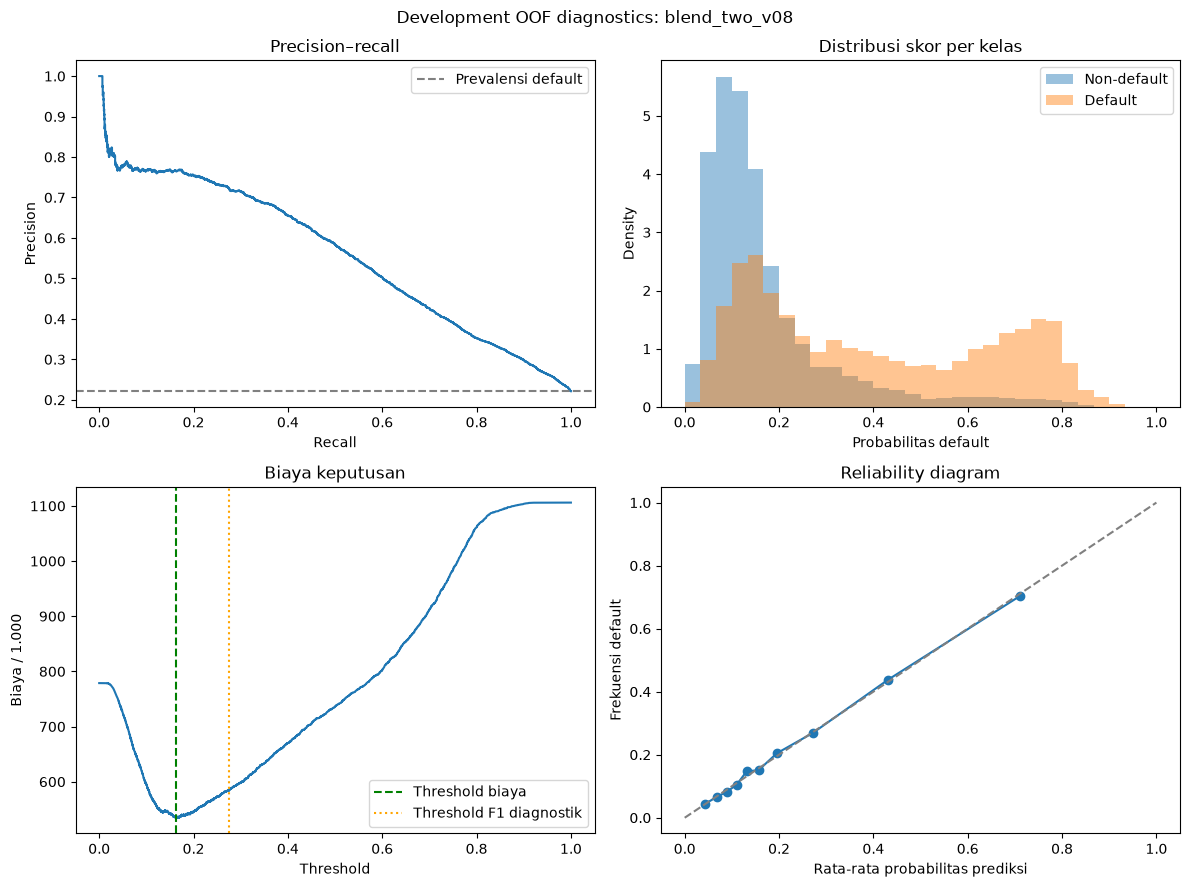

In [3]:
diagnostic_candidate = str(
    cost_comparison.iloc[0]["experiment_id"]
)

predictions = candidate_predictions[diagnostic_candidate]
policies = candidate_policies[diagnostic_candidate]
curve = candidate_curves[diagnostic_candidate]

y = predictions["y_true"].to_numpy(dtype=int)
p = predictions["probability_default"].to_numpy(dtype=float)

cost_threshold = float(
    policies.loc[
        policies["policy"].eq("cost"), "threshold"
    ].iloc[0]
)

f1_threshold = float(
    policies.loc[
        policies["policy"].eq("f1_diagnostic"), "threshold"
    ].iloc[0]
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

precision, recall, _ = precision_recall_curve(y, p)
axes[0, 0].plot(recall, precision)
axes[0, 0].axhline(
    y.mean(), linestyle="--", color="grey",
    label="Prevalensi default",
)
axes[0, 0].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision–recall",
)
axes[0, 0].legend()

bins = np.linspace(0, 1, 31)

for label, name in ((0, "Non-default"), (1, "Default")):
    axes[0, 1].hist(
        p[y == label],
        bins=bins,
        density=True,
        alpha=0.45,
        label=name,
    )

axes[0, 1].set(
    xlabel="Probabilitas default",
    ylabel="Density",
    title="Distribusi skor per kelas",
)
axes[0, 1].legend()

axes[1, 0].plot(
    curve["threshold"],
    curve["cost_per_1000"],
)
axes[1, 0].axvline(
    cost_threshold, color="green", linestyle="--",
    label="Threshold biaya",
)
axes[1, 0].axvline(
    f1_threshold, color="orange", linestyle=":",
    label="Threshold F1 diagnostik",
)
axes[1, 0].set(
    xlabel="Threshold",
    ylabel="Biaya / 1.000",
    title="Biaya keputusan",
)
axes[1, 0].legend()

observed, predicted = calibration_curve(
    y, p, n_bins=10, strategy="quantile",
)

axes[1, 1].plot(predicted, observed, marker="o")
axes[1, 1].plot(
    [0, 1], [0, 1], linestyle="--", color="grey",
)
axes[1, 1].set(
    xlabel="Rata-rata probabilitas prediksi",
    ylabel="Frekuensi default",
    title="Reliability diagram",
)

fig.suptitle(
    f"Development OOF diagnostics: {diagnostic_candidate}"
)
fig.tight_layout()

fig.savefig(
    run_dir / "oof_diagnostics.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()